# Forecasting Marrakech temperatures — exploration

This notebook walks through the data and the modelling choices behind the `tempforecast` package.
Run it from the project root after `pip install -e ".[notebook]"`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from tempforecast import data, evaluate, forecast

plt.rcParams.update({"figure.figsize": (10, 3.5), "axes.grid": True, "grid.alpha": 0.3})
df = data.load(recent=None)
print(f"{len(df):,} days from {df.index.min():%Y-%m-%d} to {df.index.max():%Y-%m-%d}")
df.tail()

9,813 days from 2000-01-01 to 2026-11-12


,tmax,tmin,rain,wind,wind_dir,radiation,sunshine,provisional
date,,,,,,,,
2026-11-08,29.5,16.1,2.9,20.1,124.0,7.97,5.318497,False
2026-11-09,25.2,18.2,1.2,11.2,357.0,12.37,10.000000,False
2026-11-10,25.4,17.7,0.6,9.6,337.0,12.94,10.000000,False
2026-11-11,27.7,17.8,4.3,27.9,208.0,4.30,1.858831,False
2026-11-12,21.7,16.5,35.3,9.6,261.0,7.54,5.685211,False


## 1. Why the first version could not work

Version 1 predicted the temperature from the **day of the week**. If the weekday mattered, the
temperatures would differ from Monday to Sunday. They do not:

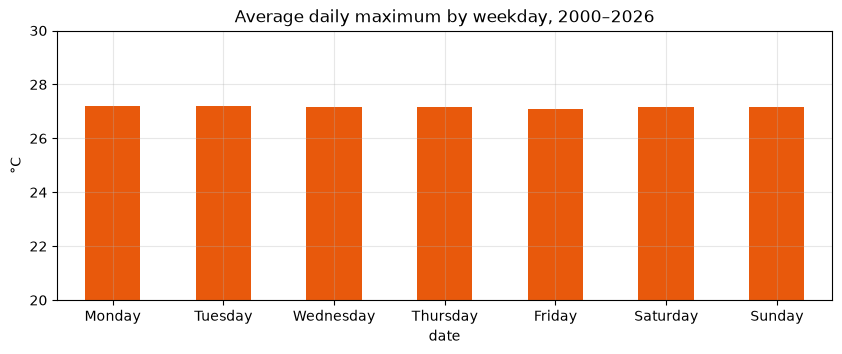

In [2]:
weekday = df.groupby(df.index.day_name())["tmax"].mean()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
ax = weekday.loc[order].plot(kind="bar", color="#e8590c", ylim=(20, 30), rot=0,
                             title="Average daily maximum by weekday, 2000–2026")
ax.set_ylabel("°C");

The averages differ by a few tenths of a degree: the weekday carries no information about the weather.
What does carry information is **the season** and **the weather of the last days**.

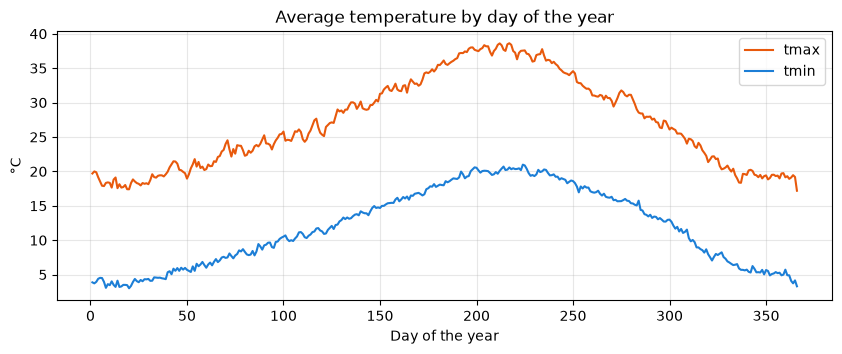

In [3]:
fig, ax = plt.subplots()
doy = df.groupby(df.index.day_of_year)[["tmax", "tmin"]].mean()
doy.plot(ax=ax, color=["#e8590c", "#1c7ed6"], title="Average temperature by day of the year")
ax.set_xlabel("Day of the year")
ax.set_ylabel("°C");

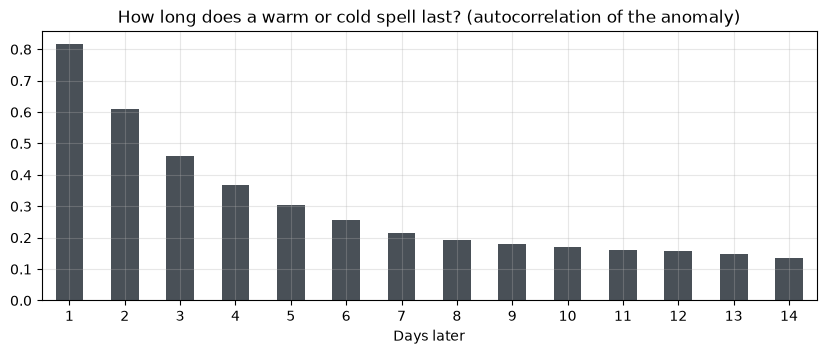

In [4]:
anomaly = df["tmax"] - df["tmax"].groupby(df.index.day_of_year).transform("mean")
lags = range(1, 15)
title = "How long does a warm or cold spell last? (autocorrelation of the anomaly)"
pd.Series([anomaly.autocorr(lag) for lag in lags], index=lags).plot(kind="bar", rot=0, color="#495057", title=title)
plt.xlabel("Days later");

An unusually warm day is usually followed by another warm day, and the link fades within a week:
this is why recent temperatures help for the next few days, and why the 7-day forecast is harder.

## 2. Honest evaluation

Models are trained on 2000–2022 and tested on 2023 onwards. Version 1 shuffled the days before splitting,
which lets a model train on days that come after the ones it is tested on.

In [5]:
# Produced by: tempforecast evaluate --output reports/scores.csv --coverage reports/coverage.csv
scores = pd.read_csv("../reports/scores.csv")
evaluate.summary(scores, horizon=1).round(2)

,mae_tmax,mae_tmin,skill_tmax,skill_tmin
model,,,,
Ensemble (ridge + boosting),1.81,1.11,0.11,0.21
Gradient boosting,1.84,1.21,0.10,0.13
Ridge regression,1.86,1.09,0.09,0.22
Persistence,2.05,1.39,0.00,0.00
Climatology,3.87,3.45,-0.89,-1.48
v1 · weekday regression,6.82,5.68,-2.33,-3.08


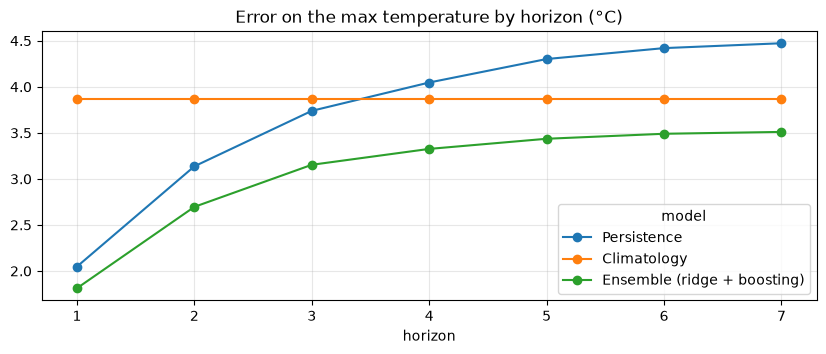

In [6]:
pivot = scores[scores["target"] == "tmax"].pivot(index="horizon", columns="model", values="mae")
pivot[["Persistence", "Climatology", "Ensemble (ridge + boosting)"]].plot(
    marker="o", title="Error on the max temperature by horizon (°C)");

In [7]:
pd.read_csv("../reports/coverage.csv")

,target,horizon,coverage,band
0,tmax,1,0.794618,±2.9 °C
1,tmin,1,0.818697,±1.8 °C
2,tmax,3,0.817989,±5.2 °C
3,tmin,3,0.792493,±2.9 °C
4,tmax,7,0.784703,±5.5 °C
5,tmin,7,0.799575,±3.4 °C


The 80% band (conformal prediction) contains the real temperature about 80% of the time on the test
years, so the uncertainty shown in the dashboard can be trusted.

## 3. The next 7 days

In [8]:
trained = forecast.train(df)
forecast.next_days(trained, df)

,horizon,tmax,tmax_low,tmax_high,tmin,tmin_low,tmin_high
date,,,,,,,
2026-11-13,1,21.9,18.9,24.8,14.1,12.4,15.9
2026-11-14,2,22.9,18.6,27.2,13.1,10.6,15.6
2026-11-15,3,23.8,18.8,28.7,13.7,10.7,16.7
2026-11-16,4,24.1,18.9,29.2,13.6,10.5,16.7
2026-11-17,5,23.9,18.5,29.4,13.9,10.6,17.2
2026-11-18,6,22.7,17.1,28.2,13.1,9.8,16.4
2026-11-19,7,23.3,17.8,28.8,12.6,9.2,16.0
